# Experiment No. 4 (Computer Laboratory – I BE AI&DS)

**Aim:**  
Implement K-Means clustering on Iris.csv dataset. Determine the number of clusters using the elbow method.

**Dataset Link:**  
`https://www.kaggle.com/datasets/uciml/iris` (Iris Species Dataset, 150 samples, 4 features).

**Objectives:**  
1. Load and inspect the `Iris.csv` dataset.
2. Extract feature attributes (`SepalLengthCm`, `SepalWidthCm`, `PetalLengthCm`, `PetalWidthCm`) for unsupervised clustering.
3. Calculate Within-Cluster Sum of Squares (WCSS / Inertia) for cluster values $K = 1$ to $10$.
4. Plot the Elbow Curve to identify the optimal number of clusters ($K = 3$).
5. Fit the K-Means clustering algorithm with $K = 3$ and assign data points to clusters.
6. Visualize the clusters along with their centroids in a 2D scatter plot.

In [1]:
# Cell 1 - Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
# Cell 2 - Load and Inspect Iris Dataset
# Load local Iris.csv or fallback to URL
url = "https://raw.githubusercontent.com/plotly/datasets/master/iris.csv"
try:
    df = pd.read_csv("Iris.csv")
except Exception:
    df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows of Iris dataset:")
display(df.head()) if 'display' in globals() else print(df.head())

# Extract features for clustering (excluding ID and categorical Species column)
feature_cols = [c for c in df.columns if c not in ['Id', 'Species', 'Name']]
X = df[feature_cols].values
print("\nFeatures used for clustering:", feature_cols)
print("Feature matrix shape:", X.shape)

Dataset Shape: (150, 6)

First 5 rows of Iris dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Features used for clustering: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
Feature matrix shape: (150, 4)


K =  1 -> WCSS = 681.37
K =  2 -> WCSS = 152.35
K =  3 -> WCSS = 78.85
K =  4 -> WCSS = 57.23
K =  5 -> WCSS = 46.45
K =  6 -> WCSS = 39.04
K =  7 -> WCSS = 34.42
K =  8 -> WCSS = 30.06
K =  9 -> WCSS = 28.33
K = 10 -> WCSS = 25.97


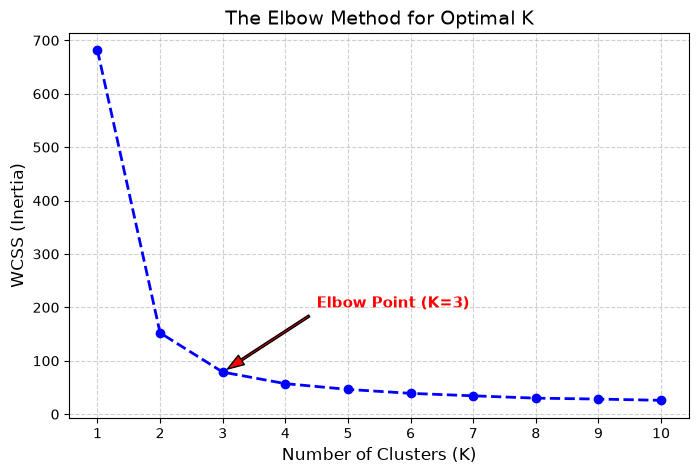

In [3]:
# Cell 3 - Determine Optimal Number of Clusters using Elbow Method
# WCSS: Within-Cluster Sum of Squares (Inertia)
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=0)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

# Display WCSS values for each K
for k, val in zip(K_range, wcss):
    print(f"K = {k:2d} -> WCSS = {val:.2f}")

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='--', color='blue', linewidth=2)
plt.title('The Elbow Method for Optimal K', fontsize=14)
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('WCSS (Inertia)', fontsize=12)
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.annotate('Elbow Point (K=3)', xy=(3, wcss[2]), xytext=(4.5, 200),
             arrowprops=dict(facecolor='red', shrink=0.05, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold', color='red')
plt.show()

In [4]:
# Cell 4 - Apply K-Means Clustering with Optimal K = 3
# Applying K-Means to the dataset with 3 clusters
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300, n_init=10, random_state=0)
y_kmeans = kmeans.fit_predict(X)

# Add cluster predictions to DataFrame
df['Cluster'] = y_kmeans

print("Cluster Assignments Count:")
print(df['Cluster'].value_counts().sort_index())

print("\nCluster Centroids (Coordinates in 4D feature space):")
centroids_df = pd.DataFrame(kmeans.cluster_centers_, columns=feature_cols)
display(centroids_df) if 'display' in globals() else print(centroids_df)

Cluster Assignments Count:
Cluster
0    62
1    50
2    38
Name: count, dtype: int64

Cluster Centroids (Coordinates in 4D feature space):
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0       5.901613      2.748387       4.393548      1.433871
1       5.006000      3.428000       1.462000      0.246000
2       6.850000      3.073684       5.742105      2.071053


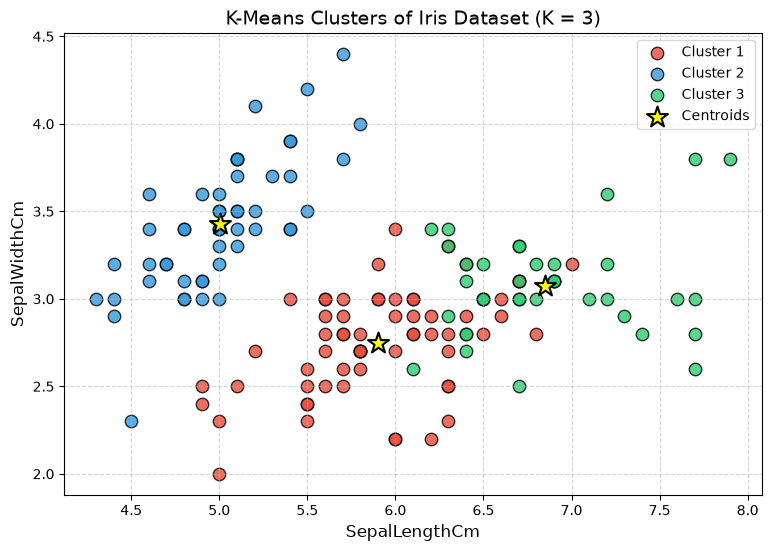

In [5]:
# Cell 5 - Visualize the Clusters and Centroids (2D Scatter Plot)
plt.figure(figsize=(9, 6))

# Plotting data points for each of the 3 clusters (using first two features: Sepal Length vs Sepal Width)
plt.scatter(X[y_kmeans == 0, 0], X[y_kmeans == 0, 1], s=80, c='#e74c3c', label='Cluster 1', edgecolors='k', alpha=0.8)
plt.scatter(X[y_kmeans == 1, 0], X[y_kmeans == 1, 1], s=80, c='#3498db', label='Cluster 2', edgecolors='k', alpha=0.8)
plt.scatter(X[y_kmeans == 2, 0], X[y_kmeans == 2, 1], s=80, c='#2ecc71', label='Cluster 3', edgecolors='k', alpha=0.8)

# Plotting the Centroids of the clusters
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=250, c='yellow',
            label='Centroids', marker='*', edgecolors='black', linewidths=1.5)

plt.title('K-Means Clusters of Iris Dataset (K = 3)', fontsize=14)
plt.xlabel(feature_cols[0], fontsize=12)
plt.ylabel(feature_cols[1], fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [6]:
# Cell 6 - Evaluation and Cross-Validation
# 1. Silhouette Score to quantify cluster separation quality
sil_score = silhouette_score(X, y_kmeans)
print(f"Silhouette Score for K = 3: {sil_score:.4f}")

# 2. Cross-tabulation comparing K-Means clusters against actual species labels
if 'Species' in df.columns:
    print("\nComparison: K-Means Clusters vs Actual Species Labels:")
    ct = pd.crosstab(df['Species'], df['Cluster'], rownames=['Actual Species'], colnames=['K-Means Cluster'])
    display(ct) if 'display' in globals() else print(ct)

Silhouette Score for K = 3: 0.5528

Comparison: K-Means Clusters vs Actual Species Labels:
K-Means Cluster   0   1   2
Actual Species             
Iris-setosa       0  50   0
Iris-versicolor  48   0   2
Iris-virginica   14   0  36
